# N2. NMF 알고리즘을 직접 짜기

**목표**
- NMF 가 "얼마나 틀렸나"를 재는 두 가지 자(제곱 오차, KL)를 이해하고, KL 이 개수 데이터의 포아송 우도와 같은 이유를 확인합니다.
- 곱셈 갱신(multiplicative update)이 경사 하강에서 어떻게 나오는지, 왜 음수가 생기지 않는지 유도합니다.
- NMF 를 처음부터 직접 짜고, scikit-learn 결과와 같은지 확인합니다.
- 초기값, 크기·순서·회전 모호함, 수렴 주의점을 봅니다.
- scikit-learn 을 쓸 때 가장 흔한 함정인 **행과 열의 방향**을 그림으로 확인합니다.

**이 노트북이 답하는 질문**: NMF 는 W 와 H 를 실제로 어떻게 계산하고, 그 결과를 읽을 때 무엇을 조심해야 하나?

**같이 볼 것**
- [N1. NMF 가 푸는 문제](lab01_what-nmf-solves.ipynb) (주스 장난감, V·W·H 의 뜻)
- 이 저장소의 [CS329Z A4: 학습](../cs329z-llms-for-builders/lab04_training.ipynb) (손실과 경사 하강), [확률 P5: 우도](../../02_statistics/probability-to-bayes/lab05_likelihood.ipynb) (포아송 우도), [행렬 M5](../linear-algebra-matrices/lab05_svd-nmf.ipynb) (곱셈 갱신 맛보기, 수렴 주의)
- Lee & Seung 2001 [PDF](https://papers.nips.cc/paper_files/paper/2000/file/f9d1152547c0bde01830b7e8bd60024c-Paper.pdf) 4·5절 [1]
- scikit-learn 1.4 [`NMF` 문서](https://scikit-learn.org/1.4/modules/generated/sklearn.decomposition.NMF.html) [4]

이 노트북의 데이터는 모두 직접 만든 장난감(시뮬레이션) 데이터입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다).
# 팔레트: Okabe-Ito. 조각(component) 번호마다 색 고정 — 1 파랑, 2 주황, 3 초록, 4 빨강, 5 하늘, 6 노랑, 7 이후 회색.
# 데이터 행렬 V 는 회색 농도, 부호 있는 값(PCA 적재량)은 빨강(+)·파랑(−), 핵심 메시지는 자주. (study_build/nmf/_palette.py 와 같음)
import logging, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Polygon
from IPython.display import display
from scipy.optimize import linear_sum_assignment, nnls
from sklearn.decomposition import NMF, PCA
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 2)
pd.set_option("display.width", 140)

COMP = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#56B4E9", "#F0E442", "#6B7280", "#9CA3AF", "#374151", "#BBBBBB"]
COMP_NAME = ["blue", "orange", "green", "red", "sky blue", "yellow", "grey", "light grey", "dark grey", "pale grey"]
V_CMAP = "Greys"
SIGNED_CMAP = "RdBu_r"
COL = dict(ink="#222222", muted="#6B7280", grid="#E5E7EB", shade="#F3F4F6", highlight="#CC79A7",
           ok="#009E73", data="#4B5563", none="#D1D5DB", light="#E5E7EB",
           matW="#374151", matH="#9CA3AF", matV="#6B7280")   # 행렬 V, W, H 상자는 회색 계열(조각 색과 섞이지 않게)


def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목'"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)


def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)


def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식을 조각으로 그린다. parts = [(mathtext, 색 또는 None, 아래 이름표 또는 None), ...]
    이름표가 조각보다 넓으면 그만큼 자리를 더 준다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        tc = COL["muted"] if color == COL["matH"] else (color or COL["ink"])   # 옅은 회색 조각도 글자는 읽히게
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left", color=tc, transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=COL["muted"] if color in (None, COL["matH"]) else color, fontweight="semibold", transform=ax.transAxes)


def show_formula(parts, title=None, height=1.6, width=11):
    """수식 조각 그림만 한 장으로"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()


def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)] — 상자와 화살표"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        boxes[k] = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                           bbox=dict(boxstyle="round,pad=0.45", facecolor=c if c != "white" else "white",
                                     alpha=0.22 if c != "white" else 1, edgecolor=c if c != "white" else COL["muted"],
                                     linewidth=1.0))
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted()
    ext = {k: t.get_bbox_patch().get_window_extent(r).transformed(inv) for k, t in boxes.items()}

    def edge_point(k, dx, dy):
        b = ext[k]; cx, cy = (b.x0 + b.x1) / 2, (b.y0 + b.y1) / 2
        hw, hh = (b.x1 - b.x0) / 2 + 0.008, (b.y1 - b.y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        ca = ((ext[a].x0 + ext[a].x1) / 2, (ext[a].y0 + ext[a].y1) / 2)
        cb = ((ext[b].x0 + ext[b].x1) / 2, (ext[b].y0 + ext[b].y1) / 2)
        dx, dy = cb[0] - ca[0], cb[1] - ca[1]
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12,
                                    shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5,
                 transform=ax.transAxes)
    ax.set_title(title)
    plt.show()


# ---------- 행렬 보여 주기 ----------
def show_matrix(df, name, meaning=None, n=5):
    """표 앞부분과 모양(행 × 열)을 함께 보여 준다"""
    print(f"{name}: {df.shape[0]} rows x {df.shape[1]} columns" + (f"   <- {meaning}" if meaning else ""))
    display(df.head(n).round(3))     # 1e-300 같은 아주 작은 값은 0.000 으로 보인다


def shapes_on(ax, n, m, k, names=("V", "W", "H"), rows="features", cols="samples", comps="components",
              captions=("data", "parts (recipes)", "amounts"), colors=None, fontsize=16):
    """V (n x m) ≈ W (n x k) x H (k x m) 를 실제 숫자로 그린 상자 그림. 크기는 로그 눈금으로 줄여 그린다."""
    sc = lambda v: 0.25 + 0.75 * math.log1p(v) / math.log1p(max(n, m, k, 30))
    hv, wv, wk = sc(n), sc(m), sc(k)
    ax.set_axis_off(); ax.set_aspect("equal")
    colors = colors or (COL["matV"], COL["matW"], COL["matH"])
    nl = chr(10)
    boxes = [(names[0], wv, hv, f"{n} {rows}{nl}x {m} {cols}", captions[0], colors[0]),
             (names[1], wk, hv, f"{n} {rows}{nl}x {k} {comps}", captions[1], colors[1]),
             (names[2], wv, wk, f"{k} {comps}{nl}x {m} {cols}", captions[2], colors[2])]
    top = max(hv, wk) / 2
    x = 0.0
    for i, (nm, w, h, dims, cap, c) in enumerate(boxes):
        ax.add_patch(FancyBboxPatch((x, -h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.02",
                                    facecolor=c, alpha=0.30, edgecolor=c, lw=1.4))
        ax.text(x + w / 2, 0.0, nm, ha="center", va="center", fontsize=fontsize, fontweight="bold", color=COL["ink"])
        ax.text(x + w / 2, -top - 0.08, dims, ha="center", va="top", fontsize=9.5, color=COL["ink"])
        ax.text(x + w / 2, top + 0.06, cap, ha="center", va="bottom", fontsize=9.5, color=COL["ink"], fontweight="semibold")
        x += w + 0.44
        if i < 2:
            ax.text(x - 0.22, 0, "≈" if i == 0 else "×", ha="center", va="center",
                    fontsize=20 if i == 0 else 18, color=COL["ink"])
    ax.set_xlim(-0.05, x - 0.39); ax.set_ylim(-top - 0.45, top + 0.28)


def draw_shapes(n, m, k, title=None, size=(11, 2.9), **kw):
    """상자 그림 한 장"""
    fig, ax = plt.subplots(figsize=size)
    shapes_on(ax, n, m, k, **kw)
    if title:
        ax.set_title(title)
    plt.show()


def heat(ax, M, rows=None, cols=None, cmap=V_CMAP, vmin=None, vmax=None, annotate=False, fmt="{:.0f}",
         fontsize=8.5, cbar=False, label=None):
    """행렬 히트맵. annotate=True 면 칸마다 숫자"""
    M = np.asarray(M, float)
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto", interpolation="nearest")
    if rows is not None:
        ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=9)
    else:
        ax.set_yticks([])
    if cols is not None:
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=9, rotation=0)
    else:
        ax.set_xticks([])
    if annotate:
        hi = np.nanmax(np.abs(M)) if M.size else 1
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                v = M[i, j]
                dark = (abs(v) > 0.55 * hi) if cmap == V_CMAP else (abs(v) > 0.6 * hi)
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize,
                        color="white" if dark else COL["ink"])
    for s in ax.spines.values():
        s.set_visible(False)
    if cbar:
        cb = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
        cb.outline.set_visible(False)
        if label:
            cb.set_label(label, fontsize=9)
    return im


# ---------- NMF 계산 도구 ----------
def fro_loss(V, R):
    """제곱 오차(Frobenius 노름의 제곱): sum (V - R)^2"""
    return float(((V - R) ** 2).sum())


def kl_loss(V, R, eps=1e-12):
    """일반화 KL: sum V log(V / R) - V + R  (V = 0 인 칸은 0 log 0 = 0)"""
    R = R + eps
    term = np.where(V > 0, V * np.log(np.where(V > 0, V, 1) / R), 0.0)
    return float((term - V + R).sum())


def nmf_mu(V, k, loss="fro", n_iter=500, seed=0, W0=None, H0=None, eps=1e-12):
    """곱셈 갱신 NMF (Lee & Seung 2001 식 4, 5). 반환: W, H, 매 반복의 손실"""
    rng = np.random.default_rng(seed)
    n, m = V.shape
    scale = math.sqrt(V.mean() / k)
    W = rng.random((n, k)) * scale + 1e-3 if W0 is None else np.array(W0, float).copy()
    H = rng.random((k, m)) * scale + 1e-3 if H0 is None else np.array(H0, float).copy()
    hist = np.empty(n_iter)
    for it in range(n_iter):
        if loss == "fro":
            H *= (W.T @ V) / (W.T @ W @ H + eps)
            W *= (V @ H.T) / (W @ H @ H.T + eps)
            hist[it] = fro_loss(V, W @ H)
        else:
            H *= (W.T @ (V / (W @ H + eps))) / (W.sum(axis=0)[:, None] + eps)
            W *= ((V / (W @ H + eps)) @ H.T) / (H.sum(axis=1)[None, :] + eps)
            hist[it] = kl_loss(V, W @ H)
    return W, H, hist


def normalize_W(W, H):
    """W 의 열을 합 1 로 맞추고 그 배수를 H 로 옮긴다(곱 WH 는 그대로)"""
    s = W.sum(axis=0)
    s[s == 0] = 1
    return W / s, H * s[:, None]


def cosine_matrix(A, B):
    """A 의 열과 B 의 열 사이 코사인 유사도 표 (A 열 수 x B 열 수)"""
    A = A / (np.linalg.norm(A, axis=0, keepdims=True) + 1e-12)
    B = B / (np.linalg.norm(B, axis=0, keepdims=True) + 1e-12)
    return A.T @ B


def match_columns(W_ref, W_est):
    """헝가리안 방법으로 W_est 의 열 순서를 W_ref 에 맞춘다. 반환: 순서, 짝마다 코사인"""
    C = cosine_matrix(W_ref, W_est)
    r, c = linear_sum_assignment(-C)
    order = c[np.argsort(r)]
    return order, C[np.arange(len(order)), order]


apply_theme()

In [2]:
# 이 노트북의 데이터와 그림 함수
FEATURES = ["sugar", "vitamin C", "fibre", "potassium", "malic acid", "beta-carotene", "anthocyanin", "iron"]
BASES = ["apple", "carrot", "berry"]
W_TRUE = np.array([[10, 4, 6], [1, 2, 6], [1, 2, 3], [3, 4, 2], [5, 0, 0], [0, 8, 0], [0, 0, 6], [0, 1, 1]], float)
H_TRUE = np.array([[2, 0, 1, 3, 0, 0, 1, 2, 0, 1, 2, 1],
                   [1, 2, 0, 0, 3, 0, 1, 0, 1, 2, 2, 1],
                   [0, 1, 2, 0, 0, 3, 1, 1, 2, 0, 1, 3]], float)
CUPS = [f"cup{j + 1}" for j in range(H_TRUE.shape[1])]
RNG = np.random.default_rng(7)
V_COUNTS = RNG.poisson(5 * W_TRUE @ H_TRUE).astype(float)     # 개수처럼 잡음 섞인 관측값


def draw_concept_map():
    nodes = {
        "loss": (0.12, 0.72, "loss: how wrong\n(squared error or KL)", COL["data"]),
        "grad": (0.38, 0.72, "gradient step\n(downhill)", COL["muted"]),
        "mu": (0.64, 0.72, "multiplicative update\nnever negative", "white"),
        "code": (0.88, 0.72, "code from scratch\n= scikit-learn", COL["ok"]),
        "init": (0.25, 0.22, "start point\n(random, NNDSVD)", "white"),
        "amb": (0.55, 0.22, "ambiguity:\nscale, order, rotation", "white"),
        "orient": (0.85, 0.22, "orientation trap:\nfeatures x samples?", "white"),
    }
    edges = [("loss", "grad", ""), ("grad", "mu", "special step size"), ("mu", "code", ""),
             ("init", "mu", ""), ("mu", "amb", "result not unique"), ("code", "orient", "reading the output")]
    concept_map(nodes, edges, title="Concept map: what N2 covers", size=(11.5, 3.6))


def draw_loss_shapes(v=4):
    lam = np.linspace(0.05, 12, 400)
    sq = (v - lam) ** 2
    kl = v * np.log(v / lam) - v + lam
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"wspace": 0.3})
    ax[0].plot(lam, sq, color=COL["ink"], lw=2)
    ax[0].plot(lam, kl, color=COL["data"], lw=2, ls="--")
    ax[0].text(7.55, 11.2, "squared error\n(v - r)^2", fontsize=9.5, color=COL["ink"], va="top")
    ax[0].text(11.9, kl[-1] + 0.5, "KL term\nv log(v/r) - v + r", fontsize=9.5, color=COL["data"], ha="right", va="bottom")
    ax[0].axvline(v, color=COL["muted"], ls=":", lw=1)
    for r_ in (v - 2, v + 2):                                  # 2 작게, 2 크게 맞춘 두 점
        k_ = v * np.log(v / r_) - v + r_
        ax[0].plot([r_, r_], [0, (v - r_) ** 2], color=COL["muted"], ls=":", lw=0.9, zorder=1)
        ax[0].plot([r_, r_], [k_, (v - r_) ** 2], "o", color=COL["ink"], ms=5, mfc="white", zorder=4)
    ax[0].set_ylim(0, 12); ax[0].set_xlabel("reconstructed value r = (WH)_ij"); ax[0].set_ylabel("loss for one cell")
    ygrid(ax[0])
    note(ax[0], v + 0.15, 11.4, f"observed v = {v}", va="top", color=COL["ink"])
    callout(ax[0], 12.4, 7.4, "off by 2 either way:\nsquared error 4 and 4\nKL 0.77 (r=2), 0.38 (r=6)", fontsize=9,
            va="center", ha="right", bbox=None)
    panel(ax[0], "A", "Two rulers for the same mistake")
    vs = np.array([2, 20, 200]); r = vs * 1.2                  # 모두 20% 크게 맞췄을 때
    sq_e = (vs - r) ** 2; kl_e = vs * np.log(vs / r) - vs + r
    xx = np.arange(3); w = 0.36
    for off, e, c, lab in [(-w / 2, sq_e, COL["ink"], "share of squared error"), (w / 2, kl_e, COL["matH"], "share of KL")]:
        sh = e / e.sum()
        ax[1].bar(xx + off, sh, width=w, color=c, label=lab)
        for x_, s_ in zip(xx + off, sh):
            pct = 100 * s_
            lab_ = f"{pct:.2f}%" if pct < 0.1 else (f"{pct:.1f}%" if pct < 10 else f"{pct:.0f}%")
            ax[1].text(x_, s_ + 0.015, lab_, ha="center", va="bottom", fontsize=8.8, color=COL["ink"])
    ax[1].set_xticks(xx); ax[1].set_xticklabels([f"count {c}" for c in vs])
    ax[1].set_ylabel("share of total loss"); ax[1].set_ylim(0, 1.12); ygrid(ax[1])
    ax[1].legend(loc="upper left", fontsize=9)
    callout(ax[1], 0.75, 0.55, "squared error grows with count^2,\nKL grows with count", ha="center", fontsize=9.5)
    panel(ax[1], "B", "Every cell 20% too high: who dominates?")
    plt.show()
    return sq_e / sq_e.sum(), kl_e / kl_e.sum()


def draw_step_paths(paths, labels, colors, title):
    fig, ax = plt.subplots(figsize=(10.5, 3.8))
    for p, lab, c in zip(paths, labels, colors):
        ax.plot(np.arange(len(p)), p, "-o", color=c, ms=3.5, lw=1.6, label=lab)
    ax.axhline(0, color=COL["ink"], lw=0.9)
    ax.axhspan(ax.get_ylim()[0] if ax.get_ylim()[0] < 0 else -0.05, 0, color=COL["muted"], alpha=0.10, lw=0)
    ax.set_xlabel("iteration"); ax.set_ylabel("value of this entry"); ygrid(ax)
    ax.legend(loc="upper right", fontsize=9.5)
    note(ax, len(paths[0]) - 1, ax.get_ylim()[0] * 0.55, "below 0 = impossible amount", ha="right", color=COL["ink"])
    panel(ax, "A", title)
    plt.show()


def draw_loss_curves(hist_fro, hist_kl):
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.7), gridspec_kw={"wspace": 0.3})
    from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter
    for a, h, nm, c in [(ax[0], hist_fro, "squared error ||V - WH||^2", COL["ink"]), (ax[1], hist_kl, "KL D(V || WH)", COL["data"])]:
        a.semilogy(np.arange(1, len(h) + 1), h, color=c, lw=2)
        a.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
        a.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}")); a.yaxis.set_minor_formatter(NullFormatter())
        a.set_xlabel("iteration"); a.set_ylabel(nm); ygrid(a)
    panel(ax[0], "A", "Squared-error updates (Theorem 1)")
    panel(ax[1], "B", "KL updates (Theorem 2)")
    callout(ax[1], 0.95, 0.85, "never goes up", ha="right", transform=ax[1].transAxes)
    plt.show()


def draw_init_curves(curves):
    fig, ax = plt.subplots(figsize=(10.5, 4.0))
    styles = {"random (seed 0)": (COL["muted"], "-"), "random (seed 1)": (COL["muted"], "--"),
              "random (seed 2)": (COL["muted"], ":"), "nndsvd": (COL["matW"], "--"), "nndsvda": (COL["ink"], "-")}
    for lab, (its, errs) in curves.items():
        c, ls = styles[lab]
        ax.plot(its, errs, ls, color=c, lw=2, marker="o", ms=3.5, label=lab)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("iterations (max_iter)"); ax.set_ylabel("reconstruction error ||V - WH||"); ygrid(ax)
    ax.legend(loc="upper right", fontsize=9)
    callout(ax, 1.05, 52, "nndsvd starts lowest, but its zeros never move:\nit stays stuck above the others", fontsize=9.5,
            ha="left", va="center", bbox=None)
    panel(ax, "A", "Same data, different starting points (scikit-learn, solver='mu')")
    plt.show()


def ternary_xy(P):
    """3 성분 비율(합 1)을 삼각형 안 점으로: 꼭짓점 A=(0,0), B=(1,0), C=(0.5, 0.866)"""
    P = np.atleast_2d(P)
    return np.column_stack([P[:, 1] + 0.5 * P[:, 2], 0.866 * P[:, 2]])


def draw_rotation(p1, p2, ranges, alts, data, err_alt):
    """ranges = ((part1 안쪽 끝, part1 바깥쪽 끝), (part2 안쪽 끝, part2 바깥쪽 끝)): 그 선분 위 어디든 맞는 답"""
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.9), gridspec_kw={"width_ratios": [1.25, 1], "wspace": 0.25})
    a = ax[0]
    tri = ternary_xy(np.eye(3))
    a.add_patch(Polygon(tri, closed=True, facecolor=COL["shade"], edgecolor=COL["muted"], lw=1))
    for v, nm, off in zip(tri, ["feature A", "feature B", "feature C"], [(-0.04, -0.06), (0.04, -0.06), (0, 0.04)]):
        a.text(v[0] + off[0], v[1] + off[1], nm, ha="center", va="center", fontsize=9.5, color=COL["ink"])
    for (inner, outer), lab in zip(ranges, ["any point here\nworks as part 1", "any point here\nworks as part 2"]):
        q0, q1 = ternary_xy(inner)[0], ternary_xy(outer)[0]
        a.plot([q0[0], q1[0]], [q0[1], q1[1]], color=COL["matH"], lw=9, alpha=0.55, solid_capstyle="round", zorder=1)
        if q1[1] < 0.02:                                   # 바깥 끝이 아래 변 위: 아래에 쓴다
            a.text(q1[0], q1[1] - 0.05, lab, ha="center", va="top", fontsize=8.8, color=COL["ink"])
        else:
            a.text(q1[0] + 0.06, q1[1], lab, ha="left", va="center", fontsize=8.8, color=COL["ink"])
    d = ternary_xy(data)
    a.plot(d[:, 0], d[:, 1], "o", color=COL["data"], ms=5, zorder=3)
    note(a, d[7, 0] + 0.05, d[7, 1], "samples", va="center", color=COL["data"])
    for p, c, nm in [(p1, COMP[0], "true part 1"), (p2, COMP[1], "true part 2")]:
        q = ternary_xy(p)[0]
        a.plot(*q, "s", color=c, ms=10, zorder=4); a.text(q[0] - 0.05, q[1], nm, ha="right", va="center", fontsize=9, color=c)
    for p in alts:
        q = ternary_xy(p)[0]
        a.plot(*q, "D", color=COL["matW"], ms=7, zorder=4)
    a.set_xlim(-0.12, 1.18); a.set_ylim(-0.12, 0.98); a.set_aspect("equal"); a.set_axis_off()
    panel(a, "A", "Each sample = a point; parts = ends of a segment")
    b = ax[1]
    feats = np.arange(3); w = 0.2
    for i, (vals, c, alpha, lab) in enumerate([(p1, COMP[0], 1, "true part 1"), (alts[1], COL["matW"], 1, "other part 1"),
                                              (p2, COMP[1], 1, "true part 2"), (alts[0], COL["matH"], 1, "other part 2")]):
        b.bar(feats + (i - 1.5) * w, vals, width=w, color=c, alpha=alpha, label=lab)
    b.set_xticks(feats); b.set_xticklabels(["feature A", "feature B", "feature C"])
    b.set_ylabel("share in the part"); b.set_ylim(0, 0.95); ygrid(b)
    b.legend(loc="upper center", ncol=2, fontsize=8.5)
    callout(b, 1.0, 0.74, f"both pairs rebuild V exactly\n(relative error {err_alt:.0e}), no negatives", ha="center", fontsize=9.5)
    panel(b, "B", "Same V, two valid W")
    plt.show()


def _block(ax, x, y, w, h, name, color, cap, dims):
    is_data = color == COL["data"]                        # 데이터 상자는 흰 바탕 + 테두리만 (W, H 의 회색과 섞이지 않게)
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=0.06",
                                facecolor="white" if is_data else color, alpha=1 if is_data else 0.32,
                                edgecolor=color, lw=1.4))
    tc = COL["ink"] if is_data or color == COL["matW"] else COL["muted"]     # 옅은 상자의 글자도 읽히게
    ax.text(x + w / 2, y + h / 2, name, ha="center", va="center", fontsize=15, fontweight="bold", color=tc)
    ax.text(x + w / 2, y + h + 0.12, cap, ha="center", va="bottom", fontsize=9.5, color=tc, fontweight="semibold")
    ax.text(x + w / 2, y - 0.12, dims, ha="center", va="top", fontsize=9.5, color=COL["ink"])
    return (x + w / 2, y, y + h)


def draw_orientation():
    fig, ax = plt.subplots(figsize=(11.5, 7.4))
    ax.set_xlim(0, 13); ax.set_ylim(-0.6, 9.4); ax.set_axis_off()
    F, S_, K = 1.4, 2.8, 0.7                              # 특징, 표본, k 의 길이(그림 단위)
    ax.text(0, 9.2, "A   Lee & Seung, Alexandrov, SigProfilerExtractor:  V (features x samples) ≈ W H",
            fontsize=11.5, fontweight="semibold", va="top")
    yA = 6.3
    v = _block(ax, 0.6, yA, S_, F, "V", COL["data"], "data", "96 features\nx 500 samples")
    ax.text(3.85, yA + F / 2, "≈", fontsize=20, ha="center", va="center")
    wA = _block(ax, 4.5, yA, K, F, "W", COL["matW"], "signatures", "96 features\nx k")
    ax.text(5.65, yA + F / 2, "×", fontsize=18, ha="center", va="center")
    hA = _block(ax, 6.2, yA + (F - K) / 2, S_, K, "H", COL["matH"], "exposures", "k\nx 500 samples")
    ax.text(0, 4.35, "B   scikit-learn NMF:  X (n_samples x n_features) ≈ W H,  with X = V.T",
            fontsize=11.5, fontweight="semibold", va="top")
    yB = 0.55
    x_ = _block(ax, 0.6, yB, F, S_, "X", COL["data"], "X = V.T", "500 samples\nx 96 features")
    ax.text(2.55, yB + S_ / 2, "≈", fontsize=20, ha="center", va="center")
    wB = _block(ax, 3.2, yB, K, S_, "W", COL["matH"], "sklearn W =\nexposures", "500 samples\nx k")
    ax.text(4.35, yB + S_ / 2, "×", fontsize=18, ha="center", va="center")
    hB = _block(ax, 4.9, yB + (S_ - K) / 2, F, K, "H", COL["matW"], "components_ =\nsignatures", "k\nx 96 features")
    note(ax, 9.6, 7.0, "same shade = same information,\nonly transposed (.T)", ha="left", va="center", fontsize=9.5,
         color=COL["ink"])
    callout(ax, 12.9, 1.2, "same problem, swapped labels:\nsklearn's W holds the exposures", ha="right", va="center")
    plt.show()


def draw_scratch_vs_sklearn(W_a, W_b, H_a, H_b, sims):
    fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.05], "wspace": 0.35})
    x = np.arange(len(FEATURES))
    for b in range(3):
        a = ax[b]
        a.bar(x - 0.18, W_a[:, b], width=0.36, color=COMP[b], label="from scratch")
        a.bar(x + 0.18, W_b[:, b], width=0.36, color=COMP[b], alpha=0.45, label="scikit-learn")
        a.set_xticks(x); a.set_xticklabels(FEATURES, rotation=60, ha="right", fontsize=9.5)
        a.set_ylim(0, 0.62); ygrid(a)
        panel(a, "ABC"[b], f"~ {BASES[b]} (cos {sims[b]:.3f})")
        if b == 0:
            a.set_ylabel("share"); a.legend(loc="upper right", fontsize=8.5)
    a = ax[3]
    for b in range(3):
        a.plot(H_a[b], H_b[b], "o", color=COMP[b], ms=6)
    lim = max(H_a.max(), H_b.max()) * 1.08
    a.plot([0, lim], [0, lim], color=COL["muted"], ls=":", lw=1)
    a.set_xlim(0, lim); a.set_ylim(0, lim); a.set_aspect("equal")
    a.set_xlabel("H from scratch"); a.set_ylabel("H from scikit-learn")
    panel(a, "D", "amounts agree")
    plt.show()

## 개념 지도

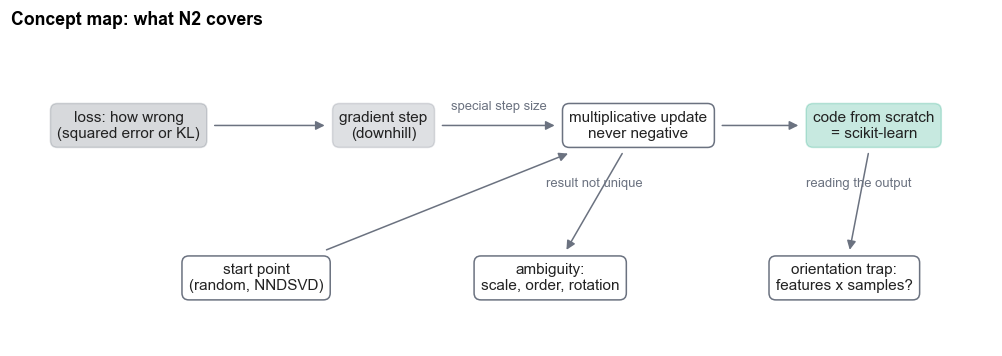

In [3]:
draw_concept_map()

**그림에서 볼 것**
- 위 줄이 계산의 흐름입니다. 손실(얼마나 틀렸나) → 내리막으로 한 걸음(경사 하강) → 걸음 크기를 특별히 고르면 곱셈 갱신이 되어 음수가 생기지 않음 → 직접 짠 코드가 scikit-learn 과 같은 답.
- 아래 줄은 결과를 읽을 때 조심할 것입니다. 출발점, 답이 하나가 아닌 문제(모호함), 그리고 행·열 방향.

## 먼저 알아 둘 것

### 1. 손실: "얼마나 틀렸나"를 숫자 하나로

**한 줄 정의**: 손실(loss, 목적 함수)은 데이터 V 와 재구성 WH 가 얼마나 다른지를 숫자 하나로 잰 값입니다. 작을수록 잘 맞습니다.

**왜 필요한가**: NMF 는 "손실이 가장 작은 W, H"를 찾는 문제입니다. 어떤 자로 재느냐에 따라 답이 달라집니다.

### 2. 경사 하강: 내리막으로 한 걸음

**한 줄 정의**: 경사 하강(gradient descent)은 손실이 가장 빨리 줄어드는 쪽(기울기의 반대쪽)으로 조금씩 움직이는 방법입니다(CS329Z A4).

**왜 필요한가**: NMF 는 공식으로 한 번에 풀 수 없어서 [1], 조금씩 고쳐 가며 손실을 줄입니다. 곱셈 갱신도 경사 하강의 한 형태입니다.

**기호 사전**: $\odot$ = 칸끼리 곱하기, 분수 막대 = 칸끼리 나누기(행렬 곱이 아님). $W^\top$ = W 의 전치(행과 열 바꾸기). $\nabla$ = 기울기(gradient).

## 1. 두 가지 자: 제곱 오차와 KL

**한 줄 정의**: 제곱 오차는 칸마다 (데이터 − 재구성)² 을 더한 것, KL(일반화 Kullback–Leibler divergence)은 칸마다 $v \log(v/r) - v + r$ 을 더한 것입니다 [1][3]. 일반화 KL 은 I-divergence 라고도 부릅니다. 보통의 KL 은 합이 1 인 확률 분포 둘을 비교하는데, V 와 WH 는 합이 1 이 아니어도 되도록 $-v + r$ 을 붙인 판입니다. 이름은 scikit-learn 안내서 [4], 합이 1 이면 보통 KL 로 돌아간다는 설명은 Lee & Seung [1] 에 있습니다.

**수식 풀어 읽기**

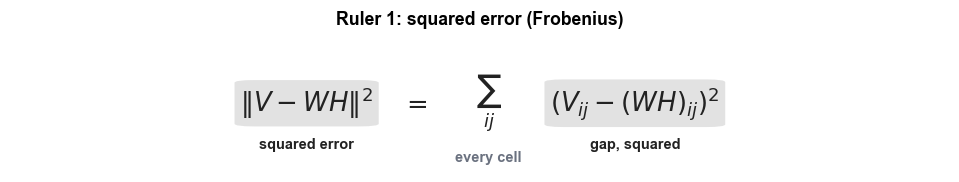

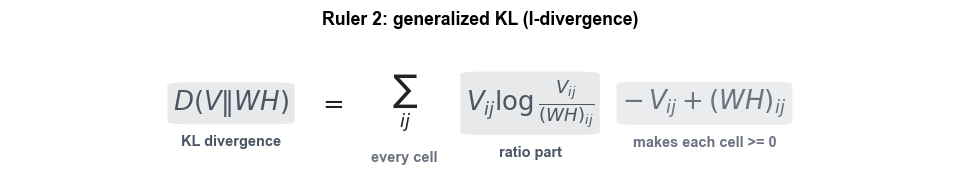

In [4]:
show_formula([(r"$\|V - WH\|^2$", COL["ink"], "squared error"), (r"$=$", None, None),
              (r"$\sum_{ij}$", None, "every cell"), (r"$(V_{ij} - (WH)_{ij})^2$", COL["ink"], "gap, squared")],
             title="Ruler 1: squared error (Frobenius)")
show_formula([(r"$D(V\|WH)$", COL["data"], "KL divergence"), (r"$=$", None, None), (r"$\sum_{ij}$", None, "every cell"),
              (r"$V_{ij}\log\frac{V_{ij}}{(WH)_{ij}}$", COL["data"], "ratio part"), (r"$-\,V_{ij} + (WH)_{ij}$", COL["muted"], "makes each cell >= 0")],
             title="Ruler 2: generalized KL (I-divergence)")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $V_{ij}$ | "브이 아이 제이" | 관측값(데이터의 한 칸) | 아래 그림 A 의 점선 v |
| $(WH)_{ij}$ | "더블유 에이치의 아이 제이 칸" | 재구성 값 r | 그림 A 의 가로축 |
| $(V_{ij}-(WH)_{ij})^2$ | "차이의 제곱" | 위로 틀리든 아래로 틀리든 똑같이 벌점 | 그림 A 의 검은 곡선 |
| $V\log\frac{V}{WH}$ | "브이 곱하기 로그 비" | 비율로 얼마나 틀렸나. r 이 v 보다 크면 음수가 된다 | 그림 A 의 회색 점선(두 항을 합친 값) |
| $-V + WH$ | "마이너스 브이 플러스 더블유 에이치" | 칸마다 벌점이 0 이상이 되고, v = r 일 때만 0 이 되게 하는 보정 | 그림 A 의 회색 점선(두 항을 합친 값) |

**숫자로 따라가기**: 2 × 2 작은 예입니다. V = [[4, 0], [2, 6]], 재구성 R = [[3, 1], [2, 5]].
- 제곱 오차 = (4−3)² + (0−1)² + (2−2)² + (6−5)² = 1 + 1 + 0 + 1 = **3**
- KL = [4 log(4/3) − 4 + 3] + [0 − 0 + 1] + [2 log 1 − 2 + 2] + [6 log(6/5) − 6 + 5] = 0.151 + 1 + 0 + 0.094 = **1.245** (V = 0 인 칸은 0 log 0 = 0 으로 봅니다. 그 칸은 "없는 것을 1 로 맞춘" 벌점 1 이 그대로 붙습니다)

In [5]:
V_s = np.array([[4, 0], [2, 6]], float); R_s = np.array([[3, 1], [2, 5]], float)
print("squared error =", fro_loss(V_s, R_s), "  KL =", round(kl_loss(V_s, R_s), 4))
assert fro_loss(V_s, R_s) == 3 and abs(kl_loss(V_s, R_s) - 1.2446) < 1e-3

squared error = 3.0   KL = 1.2447


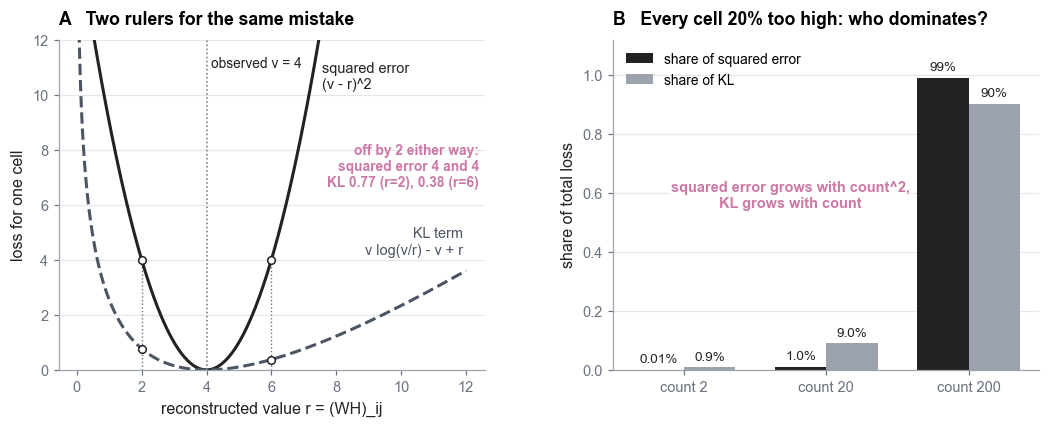

shares of counts 2 / 20 / 200:  squared error [1.0e-04 9.9e-03 9.9e-01]   KL [0.009 0.09  0.901]
v = 4:  KL at r = 2 -> 0.773   KL at r = 6 -> 0.378   squared error 4 and 4


In [6]:
share_sq, share_kl = draw_loss_shapes()
print("shares of counts 2 / 20 / 200:  squared error", np.round(share_sq, 4), "  KL", np.round(share_kl, 3))
assert share_sq[2] > 0.99 and abs(share_kl[2] - 200 / 222) < 1e-9          # KL 은 개수에 비례: 200 / (2 + 20 + 200)
kl_lo, kl_hi = 4 * np.log(4 / 2) - 4 + 2, 4 * np.log(4 / 6) - 4 + 6
print("v = 4:  KL at r = 2 ->", round(kl_lo, 3), "  KL at r = 6 ->", round(kl_hi, 3), "  squared error 4 and 4")
assert kl_lo > kl_hi

**그림에서 볼 것**
- A: 관측값이 4 일 때, 재구성 r 을 바꿔 가며 한 칸의 벌점을 그렸습니다. 제곱 오차(검은 실선)는 4 를 중심으로 좌우가 같아, 2 작게(r = 2) 맞추든 2 크게(r = 6) 맞추든 벌점이 4 로 같습니다. KL(회색 점선)은 좌우가 다릅니다. r = 2 이면 0.77, r = 6 이면 0.38 로, **모자라게 맞춘 쪽에 벌점을 더 줍니다**. r 이 0 으로 가면 KL 도 끝없이 커지지만 log 로 천천히 커집니다. 두 자는 단위가 달라서 곡선의 높이끼리는 비교하지 않습니다.
- B: 개수 2, 20, 200 인 칸을 모두 20% 크게 맞췄을 때, 전체 손실 중 각 칸의 몫입니다. 제곱 오차는 개수의 제곱에 비례해 0.01% / 1% / 99% 로, 거의 전부가 개수 200 칸에서 나옵니다. KL 은 개수에 비례해 0.9% / 9% / 90% 로 나눠 가져, 작은 개수 칸도 몫이 남습니다.

### KL 은 포아송 우도와 같다

**한 줄 정의**: 칸마다 "관측 개수 V 가 평균 WH 인 포아송 분포에서 나왔다"고 보면, 그 음의 로그 우도와 KL 은 W, H 와 상관없는 상수만큼만 다릅니다. 그래서 **KL 을 줄이는 것 = 포아송 우도를 키우는 것**입니다.

**식과 근거**: 포아송 음의 로그 우도는 $\sum_{ij} [\,r_{ij} - V_{ij}\log r_{ij} + \log V_{ij}!\,]$ 입니다(확률 P5). $V_{ij}!$ 은 계승(1 × 2 × … × $V_{ij}$)이고, 데이터만으로 정해지는 수라 W, H 와 상관없습니다. KL 은 $\sum_{ij}[\,V_{ij}\log V_{ij} - V_{ij}\log r_{ij} - V_{ij} + r_{ij}\,]$ 입니다. 빼면 $\sum_{ij}[\,\log V_{ij}! - V_{ij}\log V_{ij} + V_{ij}\,]$ 가 남는데, 여기에는 r(= WH)이 없습니다. Brunet 등도 NMF 의 divergence 가 "A 를 W 와 H 로 만들어 낼 포아송 우도와 관련된다"고 적었습니다 [3].

**시뮬레이션으로 확인**: 재구성 r 을 무작위로 여러 번 바꿔도 (포아송 음의 로그 우도 − KL)은 똑같은지 봅니다.

In [7]:
from scipy.special import gammaln
diffs = []
for s in range(5):
    R = np.random.default_rng(s).uniform(0.5, 60, V_COUNTS.shape)
    nll = float((R - V_COUNTS * np.log(R) + gammaln(V_COUNTS + 1)).sum())
    diffs.append(nll - kl_loss(V_COUNTS, R))
print("Poisson NLL - KL for 5 random reconstructions:", np.round(diffs, 6))
assert np.ptp(diffs) < 1e-6

Poisson NLL - KL for 5 random reconstructions: [230.311109 230.311109 230.311109 230.311109 230.311109]


**언제 무엇을 쓰나**

| 자 | 어울리는 데이터 | 쓴 예 |
|---|---|---|
| 제곱 오차 | 잡음이 값 크기와 상관없이 비슷한 데이터 | Lee & Seung 2001 의 Theorem 1 [1]. Alexandrov 2013 은 목표식을 제곱 오차로 적고, 답을 고를 때도 제곱 오차를 봤습니다 [5] |
| KL | 개수(read 수, 변이 수)처럼 큰 값일수록 잡음도 큰 데이터 | Brunet 2004 [3], SigProfilerExtractor [6]. Alexandrov 2013 의 결과도 "대부분 Brunet 등의 구현으로" 얻었다고 적혀 있습니다 [5] |

> **시퀀싱 데이터에서는** 변이 개수와 read 개수는 포아송처럼 흔들리는 개수라 KL 이 자연스럽습니다. SigProfilerExtractor 는 KL 을 목적 함수로 하는 곱셈 갱신 NMF 를 씁니다 [6]. 이 분야의 첫 signature 추출은 Nik-Zainal 등 2012 의 유방암 21개입니다 [9]. 이를 정리한 Alexandrov 2013 은 Step 3 의 목표식을 제곱 오차($\|reve M - P 	imes E\|_F^2$)로 적었지만, 결과는 "대부분 Brunet et al. (2004) 의 구현으로" 얻었다고 밝힙니다 [5]. Brunet 의 구현은 포아송과 관련된 divergence 를 씁니다 [3]. 어느 쪽이 "정답"이라기보다 데이터의 잡음 모양에 맞추는 선택입니다.

## 2. 곱셈 갱신: 경사 하강에서 걸음 크기를 특별히 고르기

**한 줄 정의**: 곱셈 갱신은 H(또는 W)의 각 칸에 "1 보다 크면 키우고 작으면 줄이는 비율"을 곱하는 규칙입니다. Lee 와 Seung 은 이것이 걸음 크기를 칸마다 특별히 고른 경사 하강이라는 것을 보였습니다 [1].

**유도 (제곱 오차, H 쪽)**: W 를 고정하고 H 에 대한 손실 $\tfrac12\|V - WH\|^2$ 의 기울기는 아래와 같습니다.

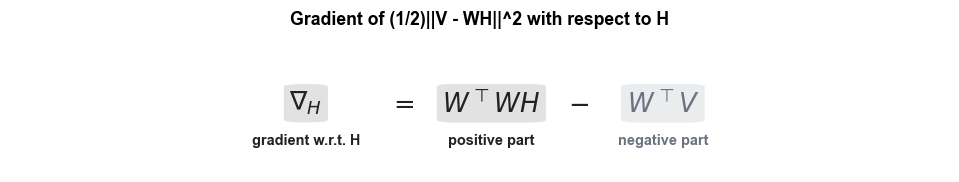

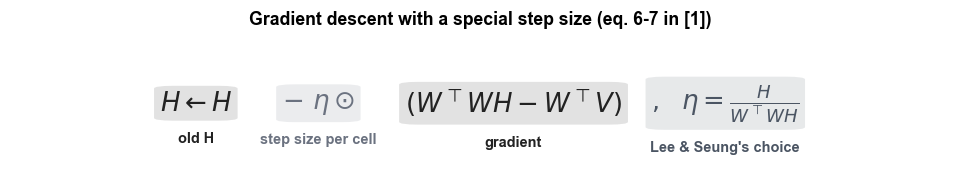

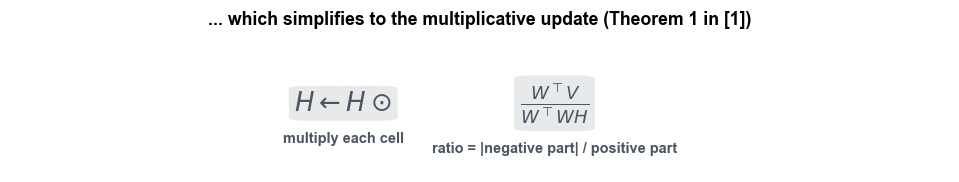

In [8]:
show_formula([(r"$\nabla_H$", COL["ink"], "gradient w.r.t. H"), (r"$=$", None, None),
              (r"$W^\top W H$", COL["ink"], "positive part"), (r"$-$", None, None),
              (r"$W^\top V$", COL["muted"], "negative part")], title="Gradient of (1/2)||V - WH||^2 with respect to H")
show_formula([(r"$H \leftarrow H$", COL["ink"], "old H"), (r"$-\ \eta \odot$", COL["muted"], "step size per cell"),
              (r"$(W^\top W H - W^\top V)$", COL["ink"], "gradient"),
              (r"$,\ \ \eta = \frac{H}{W^\top W H}$", COL["data"], "Lee & Seung's choice")],
             title="Gradient descent with a special step size (eq. 6-7 in [1])")
show_formula([(r"$H \leftarrow H \odot$", COL["data"], "multiply each cell"),
              (r"$\frac{W^\top V}{W^\top W H}$", COL["data"], "ratio = |negative part| / positive part")],
             title="... which simplifies to the multiplicative update (Theorem 1 in [1])")

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| $W^\top W H$ | "W 전치 W H" | 기울기의 + 부분. 지금의 재구성 WH 를 W 의 각 열에 비춘 값(내적)이라 0 이상 |
| $W^\top V$ | "W 전치 V" | 기울기의 − 부분에서 부호를 뗀 크기. 데이터 V 를 W 의 각 열에 비춘 값이라 0 이상 |
| $\eta$ | "에타" | 걸음 크기. 보통은 작은 상수, 여기서는 칸마다 $H/(W^\top W H)$ |
| $\frac{W^\top V}{W^\top W H}$ | "비율" | 1 보다 크면 그 칸을 키우고, 1 보다 작으면 줄인다. 완벽히 맞으면 1 이라 그대로 |

**대입하면**: $H - \frac{H}{W^\top W H}(W^\top W H - W^\top V) = H - H + H\frac{W^\top V}{W^\top WH} = H \odot \frac{W^\top V}{W^\top W H}$. Lee 와 Seung 은 이 비율이 "기울기의 + 부분을 분모에, − 부분의 크기를 분자에" 둔 것이라고 설명했습니다 [1]. W 쪽도 같은 방법으로 $W \leftarrow W \odot \frac{V H^\top}{W H H^\top}$ 가 됩니다. KL 판은 $H \leftarrow H \odot \frac{W^\top (V / WH)}{W^\top \mathbf{1}}$ 입니다(Theorem 2) [1]. 여기서 V / WH 는 칸끼리 나누기이고, $\mathbf{1}$ 은 V 와 같은 모양(n × m)에 모든 칸이 1 인 행렬입니다. 그래서 $W^\top \mathbf{1}$ 의 각 칸은 W 의 한 열의 합입니다.

**숫자로 확인**: 한 걸음을 두 방법(특별한 걸음 크기의 경사 하강, 곱셈 갱신)으로 계산해 같은지 봅니다.

In [9]:
rng = np.random.default_rng(0)
W0 = rng.random((8, 3)) + 0.1; H0 = rng.random((3, 12)) + 0.1; V0 = V_COUNTS
grad = W0.T @ W0 @ H0 - W0.T @ V0
eta = H0 / (W0.T @ W0 @ H0)
H_gd = H0 - eta * grad
H_mu = H0 * (W0.T @ V0) / (W0.T @ W0 @ H0)
assert np.allclose(H_gd, H_mu)
print("special-step gradient descent == multiplicative update:", np.allclose(H_gd, H_mu))

special-step gradient descent == multiplicative update: True


### 왜 음수가 생기지 않나

**한 줄 정의**: 0 이상인 수끼리 곱하고 나누기만 하니, 처음 W, H 가 0 보다 크면 끝까지 0 이상입니다. 보통의 경사 하강은 빼기를 하므로 0 아래로 넘어갈 수 있습니다.

**숫자로 따라가기**: 같은 출발점에서 H 의 한 칸을 따라갑니다. 음수 제한 없이 풀면 답이 음수가 되는 칸을 골랐습니다. 걸음 크기를 고정한 보통 경사 하강과 곱셈 갱신을 비교합니다.

In [10]:
LS = np.linalg.lstsq(W0, V0, rcond=None)[0]          # 음수 제한 없이 푼 답
ii, jj = np.unravel_index(LS.argmin(), LS.shape)        # 그 답이 가장 음수인 칸을 따라간다
print(f"follow H[{ii}, {jj}]: its unconstrained best value is {LS[ii, jj]:.1f} (negative)")

def follow_entry(update, n=40):
    W, H = W0.copy(), H0.copy(); path = [H[ii, jj]]
    for _ in range(n):
        H = update(W, H); path.append(H[ii, jj])
    return np.array(path)

gd_fixed = follow_entry(lambda W, H: H - 0.05 * (W.T @ W @ H - W.T @ V0))
mu_path = follow_entry(lambda W, H: H * (W.T @ V0) / (W.T @ W @ H))
print("plain gradient descent min:", round(gd_fixed.min(), 3), "  multiplicative update min:", round(mu_path.min(), 3))
assert gd_fixed.min() < 0 <= mu_path.min()

follow H[1, 3]: its unconstrained best value is -56.4 (negative)
plain gradient descent min: -40.129   multiplicative update min: 0.0


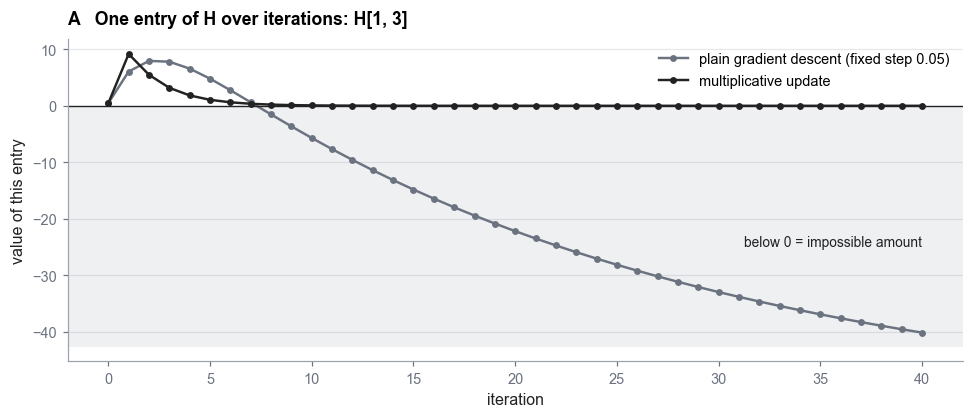

In [11]:
draw_step_paths([gd_fixed, mu_path], ["plain gradient descent (fixed step 0.05)", "multiplicative update"],
                [COL["muted"], COL["ink"]], f"One entry of H over iterations: H[{ii}, {jj}]")

**그림에서 볼 것**
- 회색: 보통 경사 하강은 이 칸을 음수 제한 없는 최적값 쪽, 곧 0 아래(옅은 회색 띠)로 데려갑니다. "양이 음수"가 되어 버려, 실제로는 0 으로 자르는 처리를 따로 해야 합니다.
- 검정: 곱셈 갱신은 비율을 곱하기만 해서 0 에 다가가되 그 아래로 내려가지 않습니다.

**주의 하나**: 어떤 칸이 정확히 0 이 되면 무엇을 곱해도 0 이라 다시 살아나지 않습니다. 그래서 출발점에 0 을 많이 넣으면 그 칸은 끝까지 0 입니다(4절의 nndsvd).

In [12]:
H_zero = H0.copy(); H_zero[0, 0] = 0.0
for _ in range(50):
    H_zero *= (W0.T @ V0) / (W0.T @ W0 @ H_zero + 1e-12)
assert H_zero[0, 0] == 0.0
print("an entry that starts at 0 stays at", H_zero[0, 0])

an entry that starts at 0 stays at 0.0


## 3. 처음부터 직접 짜기

아래가 NMF 의 전부입니다. 갱신 두 줄을 번갈아 되풀이합니다. (뒤 노트북에서도 같은 함수 `nmf_mu` 를 접힌 셀에 두고 씁니다.)

In [13]:
def nmf_scratch(V, k, loss="kl", n_iter=1000, seed=0, eps=1e-12):
    """곱셈 갱신 NMF.  V: (특징 n x 표본 m), 0 이상.  반환 W (n x k), H (k x m), 반복마다 손실."""
    rng = np.random.default_rng(seed)
    n, m = V.shape
    scale = np.sqrt(V.mean() / k)                      # 출발점의 크기를 데이터에 맞춤
    W = rng.random((n, k)) * scale + 1e-3              # 0 보다 크게 시작
    H = rng.random((k, m)) * scale + 1e-3
    hist = []
    for _ in range(n_iter):
        if loss == "fro":                              # Theorem 1 (제곱 오차)
            H *= (W.T @ V) / (W.T @ W @ H + eps)
            W *= (V @ H.T) / (W @ H @ H.T + eps)
            hist.append(fro_loss(V, W @ H))
        else:                                          # Theorem 2 (KL)
            H *= (W.T @ (V / (W @ H + eps))) / (W.sum(axis=0)[:, None] + eps)
            W *= ((V / (W @ H + eps)) @ H.T) / (H.sum(axis=1)[None, :] + eps)
            hist.append(kl_loss(V, W @ H))
    return W, H, np.array(hist)

In [14]:
show_matrix(pd.DataFrame(V_COUNTS, index=FEATURES, columns=CUPS), "V (noisy counts)",
            "5 x (W H) with Poisson noise: rows = nutrients, columns = cups")
W_f, H_f, hist_fro = nmf_scratch(V_COUNTS, 3, loss="fro", n_iter=2000)
W_k, H_k, hist_kl = nmf_scratch(V_COUNTS, 3, loss="kl", n_iter=2000)
for nm, h in [("squared error", hist_fro), ("KL", hist_kl)]:
    print(f"{nm}: start {h[0]:.1f} -> end {h[-1]:.1f};  ever went up? {bool(np.any(np.diff(h) > 1e-9 * h[0]))}")
    assert not np.any(np.diff(h) > 1e-9 * h[0])
W2, H2, _ = nmf_mu(V_COUNTS, 3, loss="kl", n_iter=2000, seed=0)      # 접힌 셀의 같은 함수
assert np.allclose(W2, W_k) and np.allclose(H2, H_k)
show_matrix(pd.DataFrame(W_k, index=FEATURES, columns=["c1", "c2", "c3"]), "W (from scratch, KL)", "8 nutrients x 3 components")
show_matrix(pd.DataFrame(H_k, index=["c1", "c2", "c3"], columns=CUPS), "H (from scratch, KL)", "3 components x 12 cups")
print(f"smallest entry of H: {H_k[H_k > 0].min():.1e}  -> shown as 0.000 above. It is ≈ 0, not exactly 0:")
print("the update keeps shrinking it toward 0, and an entry that does reach exactly 0 never revives (section 2).")

V (noisy counts): 8 rows x 12 columns   <- 5 x (W H) with Poisson noise: rows = nutrients, columns = cups


,cup1,cup2,cup3,cup4,cup5,cup6,cup7,cup8,cup9,cup10,cup11,cup12
sugar,124.0,77.0,104.0,162.0,55.0,83.0,100.0,120.0,83.0,89.0,175.0,160.0
vitamin C,23.0,47.0,74.0,12.0,30.0,94.0,34.0,40.0,66.0,15.0,56.0,116.0
fibre,21.0,38.0,34.0,14.0,46.0,48.0,37.0,35.0,41.0,26.0,54.0,62.0
potassium,48.0,49.0,32.0,25.0,58.0,37.0,47.0,37.0,46.0,53.0,88.0,71.0
malic acid,43.0,0.0,20.0,94.0,0.0,0.0,22.0,66.0,0.0,25.0,55.0,24.0


squared error: start 43126.8 -> end 1473.5;  ever went up? False
KL: start 641.1 -> end 19.6;  ever went up? False
W (from scratch, KL): 8 rows x 3 columns   <- 8 nutrients x 3 components


,c1,c2,c3
sugar,6.49,4.19,3.00
vitamin C,0.58,4.38,1.22
fibre,0.71,2.16,1.90
potassium,1.36,1.74,3.17
malic acid,3.52,0.00,0.00


H (from scratch, KL): 3 rows x 12 columns   <- 3 components x 12 cups


,cup1,cup2,cup3,cup4,cup5,cup6,cup7,cup8,cup9,cup10,cup11,cup12
c1,14.63,0.00,5.92,24.28,0.00,0.00,7.07,17.37,0.00,7.27,16.26,6.46
c2,0.00,7.79,14.86,0.00,0.00,20.86,6.93,5.75,14.13,0.00,7.46,22.95
c3,7.50,11.67,0.00,0.00,21.06,0.00,6.81,0.00,7.48,12.86,13.23,7.98


smallest entry of H: 4.9e-324  -> shown as 0.000 above. It is ≈ 0, not exactly 0:
the update keeps shrinking it toward 0, and an entry that does reach exactly 0 never revives (section 2).


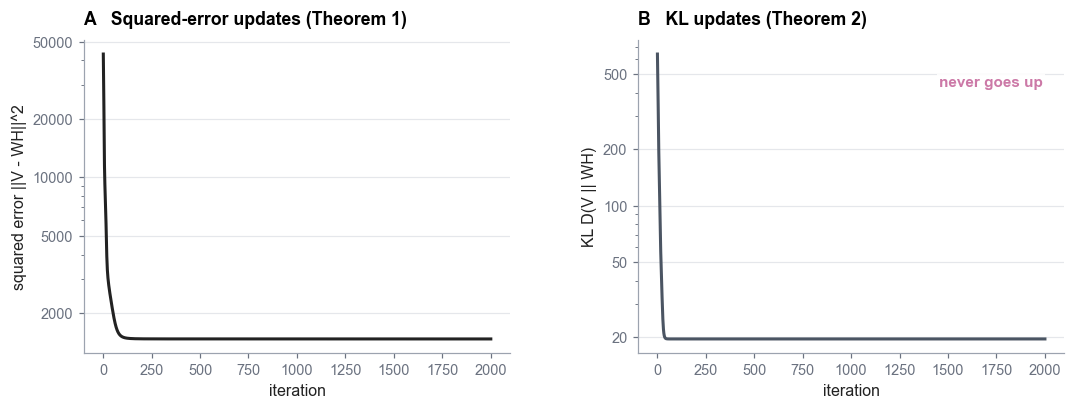

In [15]:
draw_loss_curves(hist_fro, hist_kl)

**그림에서 볼 것**
- 두 손실 모두 반복할수록 줄고, 한 번도 올라가지 않습니다(위 assert). Lee 와 Seung 의 Theorem 1·2 가 보장하는 성질입니다 [1].
- 처음 수십 번에 크게 줄고 그 뒤로는 천천히 줄어듭니다. 언제 멈출지는 사람이 정합니다(6절).

**직접 바꿔 보기**: `seed` 를 바꿔 보세요. 끝 손실은 거의 같지만 W 의 열 순서가 바뀔 수 있습니다(5절).

## 4. 출발점: 무작위 vs NNDSVD

**한 줄 정의**: 곱셈 갱신은 출발점에서 가까운 골짜기로 갑니다. 출발점을 무작위로 뽑을 수도 있고, SVD(행렬 M5)로 데이터에 맞춘 출발점(NNDSVD)을 만들 수도 있습니다 [2][4].

**왜 필요한가**: 손실이 볼록하지 않아 출발점마다 끝나는 곳이 다를 수 있습니다 [1]. 출발점을 잘 고르면 빨리 수렴하고 결과가 재현됩니다.

scikit-learn 1.4 에서 `init` 의 기본값(None)은 k 가 표본 수와 특징 수 중 작은 쪽보다 **작거나 같으면** `'nndsvda'`, 아니면 `'random'` 입니다 [4][10]. NNDSVD 는 Boutsidis 와 Gallopoulos 의 방법으로 [2], 데이터의 SVD 에서 나온 벡터를 양수 부분과 음수 부분으로 나눠 한쪽만 쓰고 나머지 칸은 0 으로 둡니다 [10]. 그래서 `'nndsvd'` 출발점에는 0 이 많습니다. scikit-learn 안내서는 기본 NNDSVD 가 "희소한(0 이 많은) 분해에 더 맞고", 0 을 데이터 평균으로 채운 NNDSVDa 등은 "0 이 적은(dense) 경우에 권한다"고 적습니다 [4].

**숫자로 따라가기**: 같은 데이터에 출발점만 바꿔, 반복 횟수마다 재구성 오차를 잽니다(`solver='mu'`).

In [16]:
SK_WARNINGS = set()

def sk_error_curve(init, seed=0, its=(1, 2, 5, 10, 20, 50, 100, 200, 500, 1000)):
    errs = []
    for it in its:
        mdl = NMF(n_components=3, init=init, solver="mu", beta_loss="frobenius", max_iter=it, tol=0, random_state=seed)
        with warnings.catch_warnings(record=True) as caught:       # scikit-learn 이 내는 경고를 모아 아래에 보여 준다
            warnings.simplefilter("always", UserWarning)
            mdl.fit(V_COUNTS.T)
        SK_WARNINGS.update(str(w.message) for w in caught if issubclass(w.category, UserWarning))
        errs.append(mdl.reconstruction_err_)
    return np.array(its), np.array(errs)

curves = {f"random (seed {s})": sk_error_curve("random", s) for s in range(3)}
curves["nndsvd"] = sk_error_curve("nndsvd"); curves["nndsvda"] = sk_error_curve("nndsvda")
final = {k: round(float(v[1][-1]), 2) for k, v in curves.items()}
print("error after 1000 iterations:", final)
for msg in sorted(SK_WARNINGS):
    print("scikit-learn warned:", msg)
assert curves["nndsvda"][1][0] < min(curves[f"random (seed {s})"][1][0] for s in range(3))   # 첫 반복의 오차가 더 작다
assert any("cannot update zeros" in m for m in SK_WARNINGS)

error after 1000 iterations: {'random (seed 0)': 38.39, 'random (seed 1)': 38.39, 'random (seed 2)': 38.39, 'nndsvd': 106.4, 'nndsvda': 38.39}
scikit-learn warned: The multiplicative update ('mu') solver cannot update zeros present in the initialization, and so leads to poorer results when used jointly with init='nndsvd'. You may try init='nndsvda' or init='nndsvdar' instead.


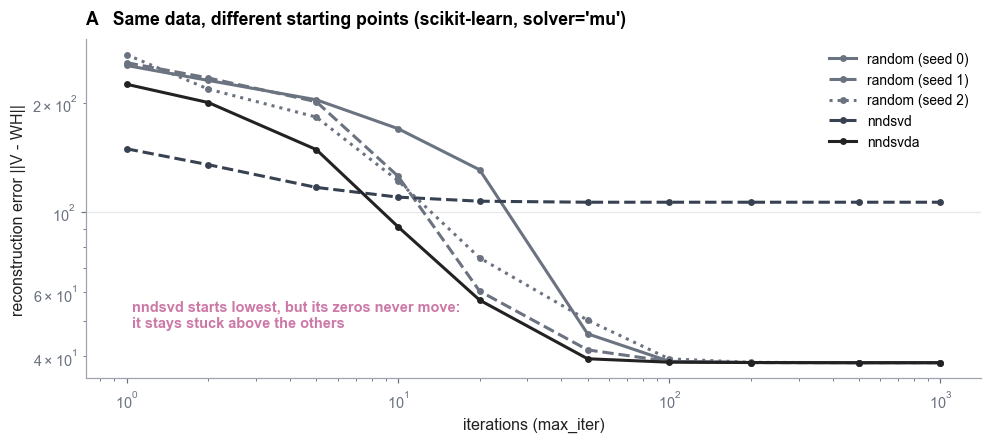

In [17]:
draw_init_curves(curves)

**그림에서 볼 것**
- 회색 세 줄(무작위 출발)은 처음 오차가 크고, 어느 정도 반복해야 따라옵니다.
- 검정 실선(nndsvda)은 SVD 로 만든 출발점이라 무작위보다 첫 반복의 오차가 작고 빨리 내려옵니다.
- 진한 회색 점선(nndsvd)은 출발점에 0 이 있어, 곱셈 갱신으로는 그 칸이 끝까지 0 입니다(2절의 주의). scikit-learn 도 이 조합에서 "'mu' solver 는 출발점의 0 을 갱신하지 못해 결과가 나빠진다"는 경고를 냅니다(위 출력). 오른쪽 끝에서 다른 출발점보다 오차가 높은지 보세요. 오차 비교는 이 노트북의 시뮬레이션 결과입니다.

**실전**: 한 번만 돌리지 말고 출발점을 바꿔 여러 번 돌려 결과가 같은지 봅니다(N3).

## 5. 답이 하나가 아닌 문제: 크기, 순서, 회전

### 5-1. 크기 모호함

**한 줄 정의**: W 의 한 열을 c 배 하고 H 의 같은 행을 1/c 배 하면 곱 WH 는 그대로입니다. 그래서 NMF 는 조각의 "크기"를 정하지 못합니다.

**수식 풀어 읽기**: 대각 행렬 D(대각선에 양수만 있는 행렬)를 끼워 넣어도 $WH = (WD)(D^{-1}H)$ 입니다.

**실전 약속**: Alexandrov 2013 은 signature 를 "변이 종류마다의 확률"로 정의해, 한 signature 의 칸을 모두 더하면 1 이 되게 했습니다(Equation 1) [5]. 그래서 W 의 열 합을 1 로 맞춥니다. 그러면 W 는 "변이 종류별 비율", H 는 "그 signature 로 생긴 변이 개수"로 읽힙니다.

In [18]:
D = np.diag([2.0, 0.5, 10.0])
assert np.allclose((W_k @ D) @ (np.linalg.inv(D) @ H_k), W_k @ H_k)
W_n, H_n = normalize_W(W_k, H_k)
assert np.allclose(W_n.sum(axis=0), 1) and np.allclose(W_n @ H_n, W_k @ H_k)
print("column sums of W before:", np.round(W_k.sum(axis=0), 2), " after:", np.round(W_n.sum(axis=0), 2))
totals = V_COUNTS.sum(axis=0)
gap_kl = normalize_W(W_k, H_k)[1].sum(axis=0) - totals         # KL 로 맞춘 결과
gap_fro = normalize_W(W_f, H_f)[1].sum(axis=0) - totals        # 제곱 오차로 맞춘 결과
print("measured totals, cups 1-4:                          ", totals[:4])
print("H column sum - measured total, KL fit:              ", np.round(gap_kl[:4], 3) + 0.0)
print("H column sum - measured total, squared-error fit:   ", np.round(gap_fro[:4], 1))
assert np.abs(gap_kl).max() < 0.05 < np.abs(gap_fro).max()

column sums of W before: [12.65 17.64 15.48]  after: [1. 1. 1.]
measured totals, cups 1-4:                           [301. 318. 337. 307.]
H column sum - measured total, KL fit:               [0. 0. 0. 0.]
H column sum - measured total, squared-error fit:    [13.3  7.8  5.7 10.1]


W 의 열 합을 1 로 맞추면, H 의 한 열의 합은 그 표본을 다시 만든 값의 총합($\sum_i (WH)_{ij}$)이 됩니다. 이것이 관측 총합과 같은지는 어떤 자로 맞췄는지에 달려 있습니다(위 출력).

- **KL 로 맞추면 정확히 같습니다.** KL 의 H 갱신 식 $H_{cj} \leftarrow H_{cj} \frac{\sum_i W_{ic} V_{ij}/(WH)_{ij}}{\sum_i W_{ic}}$ 의 양변에 $\sum_i W_{ic}$ 를 곱하고 c 에 대해 더하면, 오른쪽은 $\sum_i V_{ij} \frac{(WH)_{ij}}{(WH)_{ij}} = \sum_i V_{ij}$ 만 남습니다. 곧 갱신할 때마다 $\sum_c (\sum_i W_{ic}) H_{cj} = \sum_i V_{ij}$ 가 되고, 수렴한 답도 이 등식을 지킵니다.
- **제곱 오차로 맞추면 이런 성질이 없어** 몇 개씩 어긋납니다.

그래서 "이 컵의 영양소 중 몇이 사과 몫인가", 시퀀싱에서는 "이 종양의 변이 중 몇 개가 이 signature 몫인가"라는 읽기는 KL 로 맞췄을 때 총합과 정확히 맞습니다.

### 5-2. 순서 모호함

**한 줄 정의**: 조각에는 정해진 번호가 없습니다. 출발점이 다르면 같은 조각이 1번으로도 3번으로도 나옵니다. 두 결과를 비교할 때는 먼저 짝을 맞춥니다(코사인 유사도 + 헝가리안 방법).

In [19]:
Wa, Ha, _ = nmf_mu(V_COUNTS, 3, loss="kl", n_iter=2000, seed=0); Wa, Ha = normalize_W(Wa, Ha)
Wb, Hb, _ = nmf_mu(V_COUNTS, 3, loss="kl", n_iter=2000, seed=5); Wb, Hb = normalize_W(Wb, Hb)
print("cosine table, seed 0 columns (rows) vs seed 5 columns (cols):")
display(pd.DataFrame(cosine_matrix(Wa, Wb), index=["s0 c1", "s0 c2", "s0 c3"], columns=["s5 c1", "s5 c2", "s5 c3"]).round(3))
order_ab, sims_ab = match_columns(Wa, Wb)
print("seed-5 column order that matches seed 0:", order_ab, " cosines:", np.round(sims_ab, 4))
assert sims_ab.min() > 0.99

cosine table, seed 0 columns (rows) vs seed 5 columns (cols):


,s5 c1,s5 c2,s5 c3
s0 c1,0.46,1.00,0.56
s0 c2,0.47,0.56,1.00
s0 c3,1.00,0.46,0.47


seed-5 column order that matches seed 0: [1 2 0]  cosines: [1. 1. 1.]


표에서 각 행의 가장 큰 값(1 에 가까운 칸)이 같은 조각입니다. 헝가리안 방법(`scipy.optimize.linear_sum_assignment`)은 전체 코사인 합이 가장 크도록 한 번에 짝을 정합니다.

### 5-3. 회전 모호함: 크기·순서 말고도 답이 여러 개

**한 줄 정의**: 크기·순서를 맞춘 뒤에도, 어떤 행렬 Q 로 $W' = WQ$, $H' = Q^{-1}H$ 를 만들었을 때 **둘 다 0 이상**이면 곱은 그대로($W'H' = WH$)인 다른 답이 됩니다. 그런 Q 가 있는지는 W 와 H 에 0 이 얼마나 있는지에 달려 있습니다. Donoho 와 Stodden 은 데이터가 양수 영역의 면(face)들에 걸쳐 퍼져 있어야(0 이 넉넉해야) 답이 하나로 정해진다는 조건을 보였습니다 [8].

**숫자로 따라가기 1 (주스)**: Q 를 "대각선 1, 나머지 0.1"로 잡습니다. $WQ$ 는 0 이상끼리의 곱이라 언제나 0 이상입니다. 문제는 $Q^{-1}H$ 입니다. $Q^{-1}$ 에는 음수 칸(−0.093)이 있어서, H 에 0 이 있으면 그 자리가 음수로 내려갈 수 있습니다.

In [20]:
Q = np.eye(3) + 0.1 * (1 - np.eye(3))
Qi = np.linalg.inv(Q)
print("Q^-1 =", np.round(Qi, 3).tolist())
print("min of W Q:", round((W_TRUE @ Q).min(), 3))
print("true H (has zeros):        min of Q^-1 H     =", round((Qi @ H_TRUE).min(), 3), " -> invalid, negative amounts")
H_full = H_TRUE + 1                                # 모든 컵에 모든 재료가 1 이상 들어감 (H 에 0 없음)
print("H + 1 (every cup has all): min of Q^-1 (H+1) =", round((Qi @ H_full).min(), 3), " -> valid")
assert (Qi @ H_TRUE).min() < 0 < (Qi @ H_full).min()
assert np.allclose((W_TRUE @ Q) @ (Qi @ H_full), W_TRUE @ H_full)     # 같은 V 를 정확히 다시 만든다

Q^-1 = [[1.019, -0.093, -0.093], [-0.093, 1.019, -0.093], [-0.093, -0.093, 1.019]]
min of W Q: 0.2
true H (has zeros):        min of Q^-1 H     = -0.278  -> invalid, negative amounts
H + 1 (every cup has all): min of Q^-1 (H+1) = 0.556  -> valid


진짜 H 에는 한 재료만 넣은 컵(cup4·5·6)이 있어 0 이 많습니다. 그래서 이 Q 로 돌리면 음수가 생겨 다른 답이 되지 못합니다. H 에 1 을 더해 모든 컵에 모든 재료가 섞이게 하면, 같은 Q 로 돌린 $(WQ, Q^{-1}(H+1))$ 도 0 이상이고 V 를 정확히 다시 만듭니다. **데이터만으로는 두 답을 가를 수 없습니다.** N1 에서 "순수한 컵이 있어서 쉽게 풀렸다"고 한 것이 이 뜻입니다.

**숫자로 따라가기 2 (삼각형 그림)**: 이번에는 특징 3개(A, B, C), 진짜 재료 2개 p1 = (0.6, 0.3, 0.1), p2 = (0.1, 0.3, 0.6) 입니다. 표본은 둘을 20~80% 로 섞었습니다(순수한 표본 없음). 표본을 합 1 로 맞추면 각 표본은 삼각형 안의 점 하나이고, 모두 p1–p2 를 지나는 직선 위에 있습니다. 재료 하나를 이 직선 위 어디로 옮겨도, 모든 표본을 두 재료 "사이"에 품고 있으면(음수 양 없이) 답이 됩니다.

- part 1 의 범위: 가장 바깥 표본 (0.50, 0.30, 0.20) 부터 삼각형 가장자리 (0.70, 0.30, 0.00) 까지.
- part 2 의 범위: (0.20, 0.30, 0.50) 부터 (0.00, 0.30, 0.70) 까지.
- 범위가 가장자리에서 끝나는 이유: 특징 하나가 0 이 되면 그 점은 삼각형의 변 위에 있고, 더 나가면 그 특징이 음수가 됩니다. **어떤 특징을 한 재료만 가지면, 나머지 재료는 그 특징이 0 이라 처음부터 변 위에 놓이고 더 움직일 여지가 없습니다.** 이것이 W 쪽의 0 입니다.

In [21]:
p1 = np.array([0.6, 0.3, 0.1]); p2 = np.array([0.1, 0.3, 0.6])
alpha = np.linspace(0.2, 0.8, 15)
V_rot = np.column_stack([a * p1 + (1 - a) * p2 for a in alpha]) * 100
range1 = (0.8 * p1 + 0.2 * p2, 1.2 * p1 - 0.2 * p2)   # (가장 바깥 표본, 삼각형 변) = part 1 이 될 수 있는 범위
range2 = (0.8 * p2 + 0.2 * p1, 1.2 * p2 - 0.2 * p1)
print("part 1 range:", np.round(range1[0], 2), "->", np.round(range1[1], 2), "  part 2 range:", np.round(range2[0], 2), "->", np.round(range2[1], 2))
assert np.isclose(range1[1].min(), 0) and np.isclose(range2[1].min(), 0)    # 바깥 끝 = 특징 하나가 0 (변 위)
alt1 = 1.1 * p1 - 0.1 * p2; alt2 = 1.1 * p2 - 0.1 * p1          # 범위 안의 다른 한 쌍
W_alt = np.column_stack([alt1, alt2])
H_alt = np.column_stack([nnls(W_alt, V_rot[:, j])[0] for j in range(V_rot.shape[1])])
err_alt = np.linalg.norm(V_rot - W_alt @ H_alt) / np.linalg.norm(V_rot)
print("other valid parts:", np.round(alt1, 2), np.round(alt2, 2), " relative error:", f"{err_alt:.1e}", " min H:", round(H_alt.min(), 2))
assert err_alt < 1e-8 and H_alt.min() >= 0

part 1 range: [0.5 0.3 0.2] -> [0.7 0.3 0. ]   part 2 range: [0.2 0.3 0.5] -> [0.  0.3 0.7]
other valid parts: [0.65 0.3  0.05] [0.05 0.3  0.65]  relative error: 2.2e-16  min H: 25.0


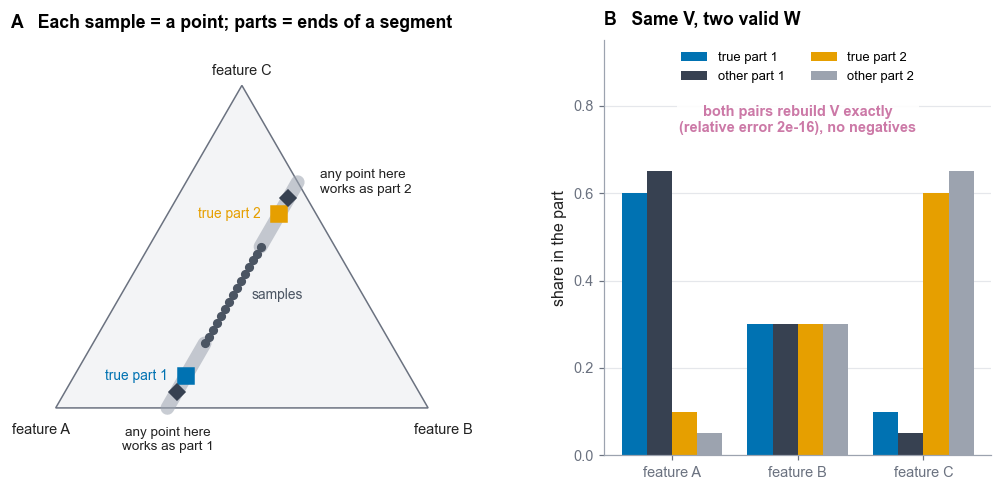

In [22]:
draw_rotation(p1, p2, (range1, range2), (alt2, alt1), (V_rot / V_rot.sum(axis=0)).T, err_alt)

**그림에서 볼 것**
- A: 회색 점(표본)은 모두 진짜 재료(파랑·주황 네모) 사이에 있습니다. 옅은 회색 굵은 띠가 각 재료가 옮겨 갈 수 있는 범위이고, 진한 회색 마름모는 그 안의 다른 한 쌍입니다. 띠는 삼각형의 변(특징 하나가 0)에서 끝납니다.
- B: 진짜 (W, H)와 마름모 쌍 모두 V 를 오차 0 으로 다시 만듭니다. 데이터만으로는 어느 쪽이 진짜인지 가를 수 없습니다.
- 답이 하나로 정해지려면 양쪽 끝이 모두 막혀야 합니다. 안쪽 끝은 **순수한 표본**(H 의 0)이, 바깥쪽 끝은 **한 재료만 가진 특징**(W 의 0)이 막습니다 [8]. 실제 데이터에서는 결과가 여러 번 돌려도 같은지(N3), 알려진 signature 와 닮았는지로 확인합니다.

> **시퀀싱 데이터에서는** 이 모호함 때문에 SigProfilerExtractor 는 NMF 를 여러 번 돌려 군집의 중심을 답으로 삼고, 이것이 "NMF 의 비유일성"에 강하다고 설명합니다 [6]. 그래도 비슷한 signature 끼리는 섞여 나올 수 있어, 추출된 signature 를 COSMIC 참조와 비교해 해석합니다 [6].

## 6. 수렴: 무엇이 보장되고 무엇이 안 되나

| | 내용 | 근거 |
|---|---|---|
| 보장 | 곱셈 갱신을 할 때마다 손실이 늘지 않는다 | Theorem 1·2 [1] |
| 보장 안 됨 | 가장 좋은 답(전체 최솟값)에 간다 | W·H 를 함께 보면 볼록하지 않아 국소 최솟값을 찾는 것이 현실적 [1] |
| 보장 안 됨 | 멈춘 곳이 정지점(조금 움직여도 1 차적으로 줄지 않는 점)이다 | Lin 2007 은 제곱 오차판 곱셈 갱신에서 이것이 아직 증명되지 않았다고 지적하고, 걸음 크기를 조금 고친 판을 내어 그 판은 증명했습니다 [7] |

Lin 이 꼽은 어려움 하나가 2절의 "0 은 다시 살아나지 않는다"입니다. H 의 한 칸이 0 인데 기울기가 음수(키워야 손실이 줄어듦)여도, 곱셈 갱신은 그 칸을 바꾸지 못합니다 [7]. Lin 의 고친 판은 이런 칸의 걸음 크기에 작은 양수를 넣어 이 문제를 피합니다.

**실전**: 손실 곡선이 평평해졌는지 보고, 출발점을 바꿔 여러 번 돌립니다. scikit-learn 은 기본 `max_iter=200`, `tol=1e-4` 입니다 [4]. 반복이 `max_iter` 에 닿았고 `tol > 0` 이면 "Maximum number of iterations … reached" 라는 `ConvergenceWarning` 을 냅니다(1.4.2 소스) [10]. 개수가 많은 데이터는 `max_iter` 를 늘려야 할 때가 많습니다.

## 7. scikit-learn 으로 쓰기, 그리고 방향 함정

**한 줄 정의**: scikit-learn 의 `NMF` 는 입력 X 를 **(표본 × 특징)** 으로 받습니다 [4]. SigProfilerExtractor 는 "행이 변이 종류, 열이 암 표본"인 행렬 M 을 씁니다 [6]. Lee & Seung 의 V ≈ WH 와 Alexandrov 2013 의 M ≈ P × E 도 (특징 × 표본) 방향입니다 [1][5].

**푸는 문제는 같습니다.** 제곱 오차와 KL 은 칸마다 벌점을 더한 값이라, 데이터와 재구성을 함께 전치해도 값이 그대로입니다($\|V - WH\|^2 = \|V^\top - H^\top W^\top\|^2$, KL 도 같음). 그래서 V.T 를 넣으면 W 와 H 가 자리만 바꿔(전치되어) 나옵니다. 바뀌는 것은 **이름표**입니다. 흔한 실수는 두 가지입니다.
1. scikit-learn 의 `W`(= `fit_transform()` 결과)를 signature 로 읽는 것. 이것은 노출량입니다.
2. 합을 1 로 맞출 때 엉뚱한 축으로 나누는 것. signature 는 **특징 방향**으로 더해 1 이 되어야 합니다(scikit-learn 에서는 `components_` 의 각 행).

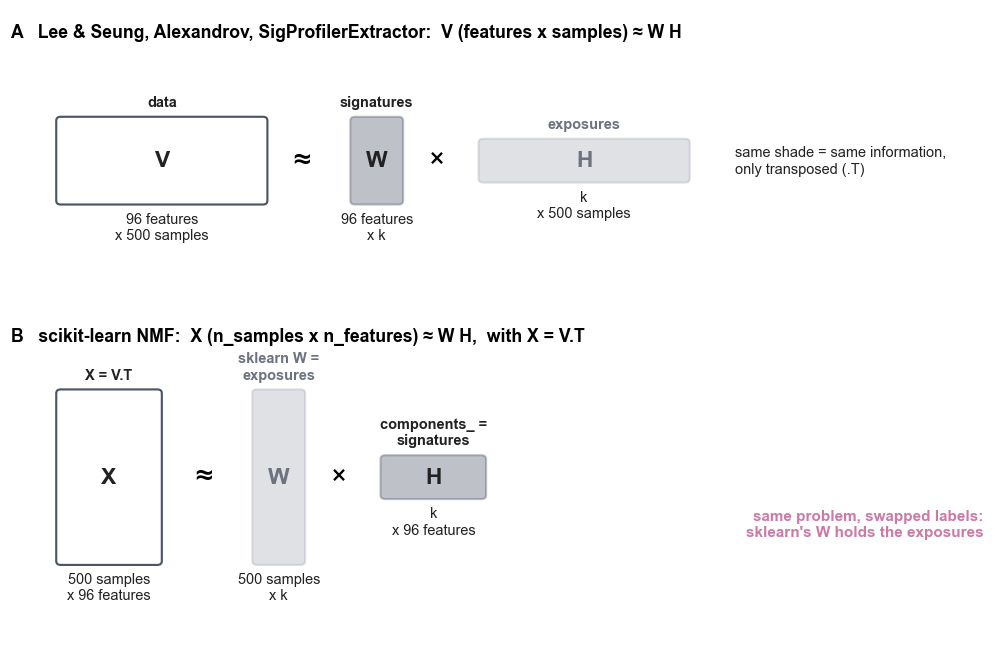

In [23]:
draw_orientation()

**그림에서 볼 것**
- A: 이 노트북의 방향. 진한 회색 W 가 signature(특징 × k), 옅은 회색 H 가 노출량(k × 표본)입니다.
- B: scikit-learn 의 방향. X 는 V 를 전치한 것(표본 × 특징)이고, scikit-learn 의 `W`(옅은 회색)는 표본 × k 인 **노출량**, `components_`(진한 회색)는 k × 특징인 **signature** 입니다.
- 같은 색끼리 같은 정보입니다. 계산은 같고 **이름표만 바뀝니다**. scikit-learn 의 `W` 를 signature 라고 읽는 순간 해석이 틀립니다.

**숫자로 확인 1**: 전치해도 손실이 같은지 봅니다.

In [24]:
R_k = W_k @ H_k
print("squared error  V vs WH:", round(fro_loss(V_COUNTS, R_k), 6), "   V.T vs (WH).T:", round(fro_loss(V_COUNTS.T, R_k.T), 6))
print("KL             V vs WH:", round(kl_loss(V_COUNTS, R_k), 6), "   V.T vs (WH).T:", round(kl_loss(V_COUNTS.T, R_k.T), 6))
assert np.isclose(kl_loss(V_COUNTS, R_k), kl_loss(V_COUNTS.T, R_k.T)) and np.isclose(fro_loss(V_COUNTS, R_k), fro_loss(V_COUNTS.T, R_k.T))

squared error  V vs WH: 1849.580798    V.T vs (WH).T: 1849.580798
KL             V vs WH: 19.556138    V.T vs (WH).T: 19.556138



**숫자로 확인 2**: 같은 데이터를 두 방향으로 돌려 같은 답이 나오는지 봅니다. 직접 짠 코드에는 V(특징 × 표본)를, scikit-learn 에는 V.T(표본 × 특징)를 넣습니다. 비교하기 쉽게 직접 짠 결과의 조각 순서를 진짜 재료 순서(apple, carrot, berry)에 맞춥니다.

In [25]:
X = V_COUNTS.T                                     # scikit-learn 입력: 12 cups x 8 nutrients
print("X for scikit-learn:", X.shape, "(n_samples, n_features)")
sk = NMF(n_components=3, init="nndsvda", solver="mu", beta_loss="kullback-leibler", max_iter=5000, tol=1e-10,
         random_state=0)
W_sklearn = sk.fit_transform(X)                    # 12 x 3  = 표본 x k  -> 노출량
H_sklearn = sk.components_                         # 3 x 8   = k x 특징  -> signature
print("sklearn fit_transform():", W_sklearn.shape, "  components_:", H_sklearn.shape)
sig_sk, exp_sk = normalize_W(H_sklearn.T, W_sklearn.T)     # 우리 방향으로 돌려놓기
sig_sc, exp_sc = normalize_W(*nmf_mu(V_COUNTS, 3, loss="kl", n_iter=5000, seed=0)[:2])
o_true, sims_true = match_columns(W_TRUE / W_TRUE.sum(axis=0), sig_sc)     # 진짜 재료 순서로
sig_sc, exp_sc = sig_sc[:, o_true], exp_sc[o_true]
print("scratch components matched to apple, carrot, berry; cosine to truth:", np.round(sims_true, 3))
o, sims_ss = match_columns(sig_sc, sig_sk)
sig_sk, exp_sk = sig_sk[:, o], exp_sk[o]
print("signature cosine, scratch vs sklearn:", np.round(sims_ss, 4))
print("exposure correlation:", round(np.corrcoef(exp_sc.ravel(), exp_sk.ravel())[0, 1], 4))
assert sims_ss.min() > 0.99 and np.corrcoef(exp_sc.ravel(), exp_sk.ravel())[0, 1] > 0.99

X for scikit-learn: (12, 8) (n_samples, n_features)
sklearn fit_transform(): (12, 3)   components_: (3, 8)
scratch components matched to apple, carrot, berry; cosine to truth: [0.996 0.996 0.999]
signature cosine, scratch vs sklearn: [1. 1. 1.]
exposure correlation: 1.0


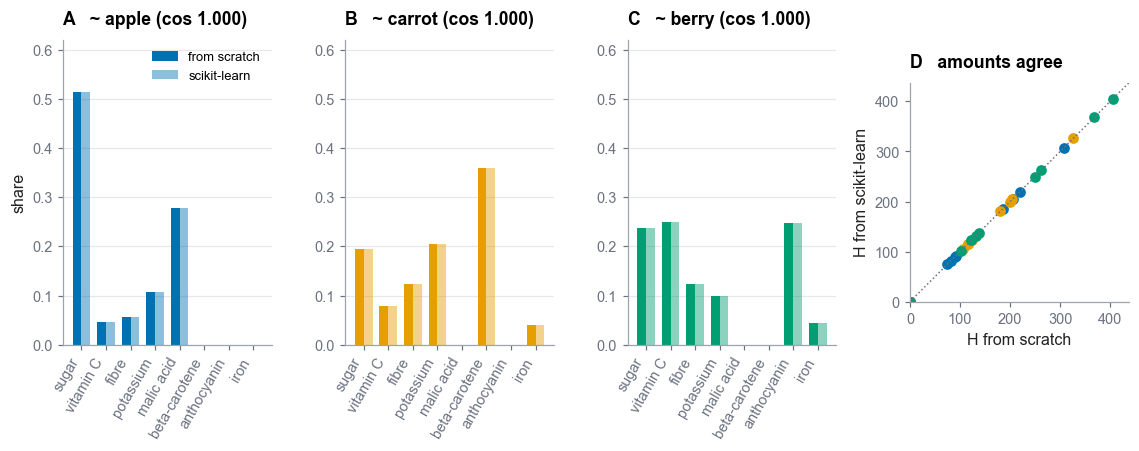

In [26]:
draw_scratch_vs_sklearn(sig_sc, sig_sk, exp_sc, exp_sk, sims_ss)

**그림에서 볼 것**
- A–C: 직접 짠 코드(진한 막대)와 scikit-learn(옅은 막대)의 signature 가 같습니다(코사인 0.99 이상). scikit-learn 쪽은 `components_.T` 를 썼습니다.
- D: 노출량도 대각선 위에서 맞습니다. scikit-learn 쪽은 `fit_transform()` 결과를 전치(`.T`)한 것입니다.

### 새 표본에 쓰기: `transform`

**한 줄 정의**: `transform(X_new)` 는 학습한 `components_`(signature)를 그대로 두고, 새 표본의 노출량만 구합니다 [4]. 이미 아는 signature 로 새 종양의 노출량을 구하는 것(행렬 M3 의 NNLS 배정)과 같은 생각입니다. 다만 계산은 다릅니다. `transform` 은 학습 때와 **같은 손실(여기서는 KL)과 같은 solver** 로 노출량만 갱신합니다(소스에서 `update_H=False`) [10]. NNLS 는 제곱 오차를 줄입니다. 그래서 두 값은 비슷하지만 똑같지는 않습니다(아래 출력).

In [27]:
X_new = RNG.poisson(5 * (W_TRUE @ np.array([[1], [0], [2]]))).T.astype(float)    # 새 컵 하나 (1 x 8)
before = sk.components_.copy()
w_new = sk.transform(X_new)                         # (1 x 3)
assert np.allclose(before, sk.components_)          # signature 는 바뀌지 않는다
print("new cup exposures (sklearn order):", np.round(w_new, 2), " shape", w_new.shape)
print("relative error:", round(np.linalg.norm(X_new - w_new @ sk.components_) / np.linalg.norm(X_new), 3))
w_nnls = nnls(sk.components_.T, X_new[0])[0]          # 같은 signature, 제곱 오차로 푼 노출량
print("same cup by NNLS (squared error):  ", np.round(w_nnls, 2))
assert not np.allclose(w_new[0], w_nnls, rtol=1e-3)            # 손실이 달라 답도 조금 다르다

new cup exposures (sklearn order): [[0.   0.91 1.34]]  shape (1, 3)
relative error: 0.104
same cup by NNLS (squared error):   [0.03 0.98 1.32]


**자주 쓰는 인자** (scikit-learn 1.4 `NMF` [4])

| 인자 | 뜻 | 고를 때 |
|---|---|---|
| `n_components` | k, 조각 수 | N3 의 방법으로 고른다 |
| `init` | 출발점. None 이면 조건에 따라 `'nndsvda'` 또는 `'random'` | 여러 번 돌릴 때는 `'random'` + `random_state` 를 바꿔 가며 |
| `solver` | `'cd'`(좌표 하강, 기본) 또는 `'mu'`(곱셈 갱신) | KL 을 쓰려면 `'mu'` (제곱 오차가 아닌 손실은 `'mu'` 에서만 쓰임) |
| `beta_loss` | `'frobenius'`(제곱 오차, 기본), `'kullback-leibler'` 등 | 개수 데이터는 `'kullback-leibler'` |
| `max_iter`, `tol` | 최대 반복 수(기본 200), 멈춤 기준(기본 1e-4) | 경고가 나면 `max_iter` 를 늘린다 |
| `random_state` | 무작위 출발점·좌표 하강의 씨앗 | 결과를 다시 만들려면 고정 |
| `fit_transform(X)` 반환 | (표본 × k) | **노출량** |
| `components_` | (k × 특징) | **signature** |

위 표의 동작은 모두 scikit-learn 1.4 문서 [4] 와 1.4.2 소스 [10] 에서 확인한 것입니다. 다른 판은 기본값이 다를 수 있습니다.

**직접 바꿔 보기**: `beta_loss="kullback-leibler"` 에 `solver="cd"` 를 주면 어떻게 되는지 실행해 보세요(오류가 납니다).

In [28]:
# NMF(n_components=3, solver="cd", beta_loss="kullback-leibler").fit(X)

## 연습 문제

1. V = [[2]], R = [[1]] 한 칸일 때 제곱 오차와 KL 은 각각 얼마입니까?
2. 곱셈 갱신의 비율 $\frac{W^\top V}{W^\top W H}$ 가 모든 칸에서 1 이면 무슨 뜻입니까?
3. scikit-learn 으로 (종양 300 × 96) 표를 분해했습니다. `components_` 의 모양과 뜻은? `fit_transform()` 결과의 모양과 뜻은?
4. 어떤 칸이 0 에서 출발했는데, 데이터상 그 칸은 0 이 아니어야 합니다. 곱셈 갱신만 쓰면 어떻게 됩니까?
5. 실수로 (96 × 300) 표를 전치하지 않고 그대로 scikit-learn 에 넣었습니다. 손실은 달라집니까? 결과는 어떻게 읽어야 합니까?

<details><summary>정답 보기</summary>

1. 제곱 오차 = (2−1)² = 1. KL = 2 log 2 − 2 + 1 = 0.386.
2. 그 칸들은 더 바꿀 것이 없다는 뜻입니다. 완벽히 맞으면(V = WH) 비율이 1 이라, 완벽한 재구성은 갱신의 고정점입니다 [1].
3. `components_` 는 (k × 96) 으로 signature, `fit_transform()` 은 (300 × k) 로 노출량입니다.
4. 끝까지 0 입니다. 그래서 0 이 없는 출발점(무작위, nndsvda)을 씁니다.
5. 손실은 같습니다(칸마다 더한 값이라 전치해도 그대로). 이름표만 바뀝니다. 이때는 `fit_transform()` 결과 (96 × k) 가 signature, `components_` (k × 300) 가 노출량입니다. signature 의 합 1 은 `fit_transform()` 결과의 각 열로 맞춥니다.

</details>

In [29]:
assert fro_loss(np.array([[2.0]]), np.array([[1.0]])) == 1
assert abs(kl_loss(np.array([[2.0]]), np.array([[1.0]])) - (2 * np.log(2) - 1)) < 1e-9
print("exercise checks passed")

exercise checks passed


## 정리

- 손실은 두 가지를 주로 씁니다. 제곱 오차는 큰 값에 끌려가고, KL 은 포아송 우도와 같아 개수 데이터에 어울립니다.
- 곱셈 갱신은 걸음 크기를 칸마다 특별히 고른 경사 하강이고, 비율을 곱하기만 해서 음수가 생기지 않습니다. 손실은 늘지 않지만 가장 좋은 답에 간다는 보장은 없습니다.
- 직접 짠 열 줄 남짓의 코드가 scikit-learn 과 같은 답을 냅니다.
- 결과는 크기·순서·회전이 모호합니다. W 의 열 합을 1 로 맞추고, 코사인으로 짝을 맞추고, 여러 번 돌려 확인합니다.
- scikit-learn 은 (표본 × 특징)을 받으므로 `fit_transform()` 이 노출량, `components_` 가 signature 입니다. 푸는 문제는 같고 이름표만 바뀝니다.

다음 N3 에서는 k 를 어떻게 고르는지 봅니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Lee DD, Seung HS. Algorithms for Non-negative Matrix Factorization. *Advances in Neural Information Processing Systems 13* (NIPS 2000). [PDF](https://papers.nips.cc/paper_files/paper/2000/file/f9d1152547c0bde01830b7e8bd60024c-Paper.pdf). 3절(Problem 1·2, 볼록하지 않음), 4절(Theorem 1·2, 식 4·5, 완벽한 재구성은 고정점), 5절(식 6–9, 걸음 크기 $\eta = H/(W^\top WH)$, "positive component of the gradient in the denominator")을 확인. | 1·2·3·6절 |
| [2] | Boutsidis C, Gallopoulos E (2008). SVD based initialization: A head start for nonnegative matrix factorization. *Pattern Recognition* 41(4):1350–1362. [doi:10.1016/j.patcog.2007.09.010](https://doi.org/10.1016/j.patcog.2007.09.010). Crossref 서지 정보만 확인. 방법의 설명은 [4] 의 사용자 안내서 문장을 따름. | 4절 |
| [3] | Brunet J-P 외 (2004). Metagenes and molecular pattern discovery using matrix factorization. *PNAS* 101(12):4164–4169. [PMC384712](https://pmc.ncbi.nlm.nih.gov/articles/PMC384712/). Methods 의 divergence 식과 "related to the Poisson likelihood" 문장을 확인. | 1절 |
| [4] | scikit-learn 1.4 문서. [`sklearn.decomposition.NMF`](https://scikit-learn.org/1.4/modules/generated/sklearn.decomposition.NMF.html) (X 의 모양 (n_samples, n_features), `init` 기본값 규칙, `solver`, `beta_loss` "Used only in 'mu' solver", `max_iter=200`, `tol=1e-4`, `components_` (n_components, n_features), `transform` 반환 W (n_samples, n_components)), [User Guide 2.5.7](https://scikit-learn.org/1.4/modules/decomposition.html#non-negative-matrix-factorization-nmf-or-nnmf) (KL 식과 "also referred as I-divergence", "The basic NNDSVD algorithm is better fit for sparse factorization", NNDSVDa 는 "recommended in the dense case"). | 1·4·6·7절 |
| [5] | Alexandrov LB 외 (2013). Deciphering signatures of mutational processes operative in human cancer. *Cell Reports* 3(1):246–259. [PMC3588146](https://pmc.ncbi.nlm.nih.gov/articles/PMC3588146/). Experimental Procedures Step 3 의 $\min \|\breve M - P\times E\|_F^2$ 와 "the results reported here were deriving mostly using the implementation in Brunet et al. (2004)", Equation 1(signature 의 칸은 확률이라 합이 1), M ≈ P × E 를 확인. | 1·5·7절 |
| [6] | Islam SMA, Díaz-Gay M 외 (2022). Uncovering novel mutational signatures by de novo extraction with SigProfilerExtractor. *Cell Genomics* 2(11):100179. [PMC9646490](https://pmc.ncbi.nlm.nih.gov/articles/PMC9646490/). "multiplicative update NMF algorithm … Kullback-Leibler divergence", "resistant to … the lack of uniqueness of NMF", COSMIC 와 맞추기, STAR Methods 의 "a mutational matrix M with t rows and n columns; rows represent mutational channels while columns reflect individual cancer samples" 를 확인. | 1·5·7절 |
| [7] | Lin C-J (2007). On the convergence of multiplicative update algorithms for nonnegative matrix factorization. *IEEE Transactions on Neural Networks* 18(6):1589–1596. [doi:10.1109/TNN.2007.895831](https://doi.org/10.1109/TNN.2007.895831). 저자 사본([PDF](http://www0.cs.ucl.ac.uk/staff/Y.Ying/reading/multconv.pdf))의 초록("for the common NMF approach of minimizing the Euclidean distance … no proof has shown that multiplicative updates converge to a stationary point", "We propose slight modifications of existing updates and prove their convergence"), "there is no proof yet showing that any limit point is stationary", 그리고 어려움 2("If H_bj … is zero, and the gradient … < 0, H_bj is not changed")를 확인. | 6절 |
| [8] | Donoho D, Stodden V. When Does Non-Negative Matrix Factorization Give a Correct Decomposition into Parts? *Advances in Neural Information Processing Systems 16* (NIPS 2003). [초록 쪽](https://proceedings.neurips.cc/paper/2003/hash/1843e35d41ccf6e63273495ba42df3c1-Abstract.html). 초록("under certain conditions, basically requiring that some of the data are spread across the faces of the positive orthant, there is a unique such simplicial cone")을 확인. | 5절 |
| [9] | Nik-Zainal S, Alexandrov LB, Wedge DC 외 (2012). Mutational processes molding the genomes of 21 breast cancers. *Cell* 149(5):979–993. [doi:10.1016/j.cell.2012.04.024](https://doi.org/10.1016/j.cell.2012.04.024), PMID 22608084. 초록("applied mathematical methods to extract mutational signatures")을 확인. | 1절 |
| [10] | scikit-learn 1.4.2 소스 [`sklearn/decomposition/_nmf.py`](https://github.com/scikit-learn/scikit-learn/blob/1.4.2/sklearn/decomposition/_nmf.py). 설치된 1.4.2 에서 `_initialize_nmf` 의 `n_components <= min(n_samples, n_features)` 규칙(299–303 줄), NNDSVD 가 SVD 벡터의 양수·음수 부분을 나누고 작은 값을 0 으로 두는 부분, `_fit_transform` 의 `n_iter == self.max_iter and self.tol > 0` 일 때의 `ConvergenceWarning`(1769–1775 줄), `transform` 이 `update_H=False` 로 같은 solver 를 부르는 부분(1799 줄)을 확인. | 4·6·7절 |

주스 데이터, 손실 값, 출발점 비교, 회전 예는 모두 **이 노트북의 시뮬레이션 결과**입니다.